# Basic interpolation using $s$

Here, $s$ goes from 0 to 1. It describes progress from the start point to the goal point. We first create a small set of points on a parabolic curve, then interpolate positions for arbitrary values of $s$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Generate a parabola from values of $s$

For a simple example, use $x(s)=s$ and $z(s)=4h s(1-s)$. The motion starts at $(0,0)$, reaches height $h$ at $s=0.5$, and finishes at $(1,0)$.

In [5]:
# Only six known samples, so the interpolation is easy to see.
s_known = np.linspace(0.0, 1.0, 7)
height = 0.25

x_known = s_known
z_known = 4.0 * height * s_known * (1.0 - s_known)

print("s values:", s_known)
print("x values:", x_known)
print("z values:", z_known)

s values: [0.         0.16666667 0.33333333 0.5        0.66666667 0.83333333
 1.        ]
x values: [0.         0.16666667 0.33333333 0.5        0.66666667 0.83333333
 1.        ]
z values: [0.         0.13888889 0.22222222 0.25       0.22222222 0.13888889
 0.        ]


## 2. Interpolate at new values of $s$

`np.interp` finds the two surrounding known samples and linearly interpolates between them.

In [6]:
# These query values do not have to be in s_known.
s_query = np.array([0.05, 0.17, 0.33, 0.52, 0.78, 0.93])

x_query = np.interp(s_query, s_known, x_known)
z_query = np.interp(s_query, s_known, z_known)

for s, x, z in zip(s_query, x_query, z_query):
    print(f"s={s:.2f} -> interpolated position = ({x:.3f}, {z:.3f})")

s=0.05 -> interpolated position = (0.050, 0.042)
s=0.17 -> interpolated position = (0.170, 0.141)
s=0.33 -> interpolated position = (0.330, 0.221)
s=0.52 -> interpolated position = (0.520, 0.247)
s=0.78 -> interpolated position = (0.780, 0.166)
s=0.93 -> interpolated position = (0.930, 0.058)


## 3. Plot the known and interpolated points

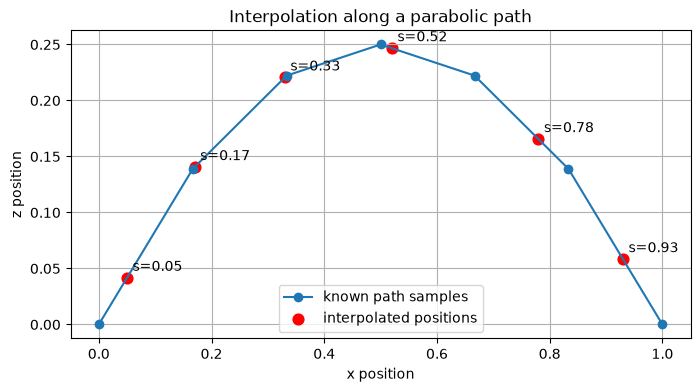

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(x_known, z_known, "o-", label="known path samples")
plt.scatter(x_query, z_query, color="red", s=60, label="interpolated positions")

for s, x, z in zip(s_query, x_query, z_query):
    plt.annotate(f"s={s:.2f}", (x, z), xytext=(4, 5), textcoords="offset points")

plt.xlabel("x position")
plt.ylabel("z position")
plt.title("Interpolation along a parabolic path")
plt.grid(True)
plt.legend()
plt.show()

## 4. The same idea with 80 path points and 9 MPC references

This resembles the repository more closely. The 80 values describe the complete path. The 9 query values represent one possible MPC reference horizon.

MPC s values: [0.3  0.32 0.34 0.36 0.38 0.4  0.42 0.44 0.46]
MPC reference points [x, z]:
[[0.3        0.20996635]
 [0.32       0.2175677 ]
 [0.34       0.22438071]
 [0.36       0.23036052]
 [0.38       0.23559686]
 [0.4        0.23996154]
 [0.42       0.24357635]
 [0.44       0.24637077]
 [0.46       0.24836404]]


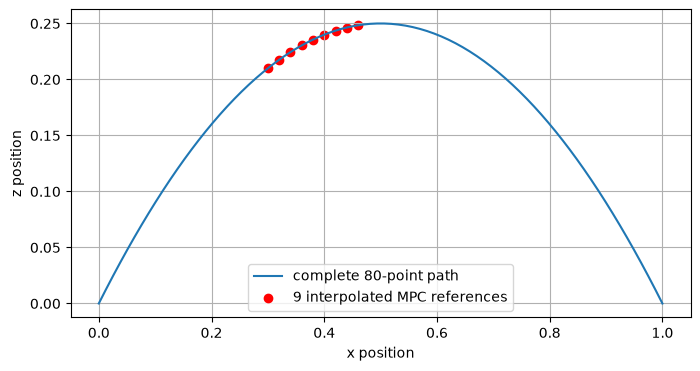

In [8]:
s_path = np.linspace(0.0, 1.0, 80)
x_path = s_path
z_path = 4.0 * height * s_path * (1.0 - s_path)

# Example: current progress is s=0.30 and the horizon looks ahead.
s_progress = 0.30
s_step = 0.02
s_mpc = np.clip(s_progress + s_step * np.arange(9), 0.0, 1.0)

x_ref = np.interp(s_mpc, s_path, x_path)
z_ref = np.interp(s_mpc, s_path, z_path)

print("MPC s values:", s_mpc)
print("MPC reference points [x, z]:")
print(np.column_stack((x_ref, z_ref)))

plt.figure(figsize=(8, 4))
plt.plot(x_path, z_path, label="complete 80-point path")
plt.scatter(x_ref, z_ref, color="red", label="9 interpolated MPC references")
plt.xlabel("x position")
plt.ylabel("z position")
plt.grid(True)
plt.legend()
plt.show()